# 02 — Baseline de persistência × modelos de previsão

**Pergunta 1 do projeto:** dá para prever o preço médio da gasolina comum em AL
nas próximas semanas melhor do que simplesmente repetir o último preço?

Regras que este notebook respeita (CLAUDE.md):

- **Defasagem de publicação.** A ANP publica com ~1 a 2 semanas de atraso. Ao
  prever a semana *N*, o último dado disponível é o da semana *N − d*. O caso
  principal usa **d = 2** (conservador); d = 1 é mostrado como sensibilidade.
- **Split temporal.** Treino até 31/12/2023, teste de 2024 em diante. Nada de
  embaralhar. Padronização (`StandardScaler`) ajustada só no treino.
- **Baseline a bater:** persistência — ŷ(N) = y(N − d).
- **Série-alvo:** índice estadual de **pesos fixos** (Maceió + Arapiraca), só
  gasolina comum, mediana dos postos por semana. Os outros três municípios
  entram e saem da pesquisa por meses e confundiriam preço com composição da
  amostra (ver `src/series.py` e `docs/observacoes_base.md`).

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))
from series import carregar_comum, painel_municipios, indice_estadual, preco_posto_semana

DOCS = RAIZ / "docs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

comum = carregar_comum()
preco, n_postos = painel_municipios(comum)
indice = indice_estadual(preco)
ULTIMA_COLETA = comum["data_coleta"].max()
print(f"gasolina comum: {len(comum):,} linhas | semanas no calendário: {len(preco)}")
print(f"dado mais recente: coleta de {ULTIMA_COLETA:%d/%m/%Y}")
print(f"semanas com índice estadual definido: {indice.notna().sum()} de {len(indice)}")

gasolina comum: 19,366 linhas | semanas no calendário: 400
dado mais recente: coleta de 26/08/2026
semanas com índice estadual definido: 369 de 400


## 1. A série-alvo

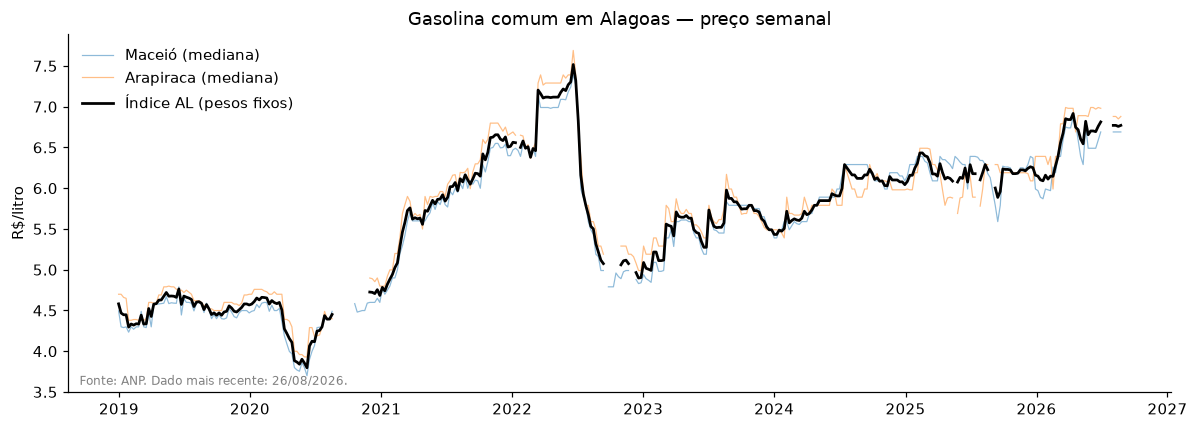

In [2]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(preco.index, preco["MACEIO"], lw=0.8, alpha=0.5, label="Maceió (mediana)")
ax.plot(preco.index, preco["ARAPIRACA"], lw=0.8, alpha=0.5, label="Arapiraca (mediana)")
ax.plot(indice.index, indice, lw=1.8, color="black", label="Índice AL (pesos fixos)")
ax.set_ylabel("R$/litro")
ax.set_title("Gasolina comum em Alagoas — preço semanal")
ax.text(0.01, 0.02, f"Fonte: ANP. Dado mais recente: {ULTIMA_COLETA:%d/%m/%Y}.",
        transform=ax.transAxes, fontsize=8, color="gray")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(DOCS / "fig_serie_indice.png", bbox_inches="tight")
plt.show()

## 2. Features — só o que já estaria publicado

Tudo é expresso **relativo ao último preço conhecido** y(N − d), e o alvo é a
variação y(N) − y(N − d). Assim o modelo aprende "quanto o preço vai mudar",
e a persistência corresponde a prever variação zero.

- lags do índice: y(N − d − k) − y(N − d), k = 1..3 (tendência recente)
- lags de Maceió no mesmo formato
- médias móveis de 4 e 8 semanas menos o último preço (reversão à média)
- semana do ano (seno/cosseno)

In [3]:
def montar(serie, maceio, d):
    ultimo = serie.shift(d)
    X = pd.DataFrame(index=serie.index)
    for k in range(1, 4):
        X[f"lag_{d+k}"] = serie.shift(d + k) - ultimo
        X[f"maceio_lag_{d+k}"] = maceio.shift(d + k) - ultimo
    X["maceio_lag_{}".format(d)] = maceio.shift(d) - ultimo
    X["mm4"] = serie.shift(d).rolling(4, min_periods=3).mean() - ultimo
    X["mm8"] = serie.shift(d).rolling(8, min_periods=6).mean() - ultimo
    semana = serie.index.isocalendar().week.to_numpy(dtype=float)
    X["sem_sin"] = np.sin(2 * np.pi * semana / 52)
    X["sem_cos"] = np.cos(2 * np.pi * semana / 52)
    alvo = serie - ultimo
    ok = X.notna().all(axis=1) & alvo.notna()
    return X[ok], alvo[ok]

CORTE = pd.Timestamp("2024-01-01")
X, alvo = montar(indice, preco["MACEIO"], d=2)
treino, teste = X.index < CORTE, X.index >= CORTE
print(f"treino: {treino.sum()} semanas ({X.index[treino].min():%m/%Y} a {X.index[treino].max():%m/%Y})")
print(f"teste:  {teste.sum()} semanas ({X.index[teste].min():%m/%Y} a {X.index[teste].max():%m/%Y})")

treino: 211 semanas (02/2019 a 12/2023)
teste:  115 semanas (01/2024 a 06/2026)


## 3. Comparação no período de teste

Três famílias:

1. **Persistência** (baseline) e **média móvel de 4 semanas**.
2. **Modelos com split fixo** — Ridge e Gradient Boosting treinados uma vez em 2019–2023.
3. **Ridge walk-forward** — retreinado a cada semana com as últimas 156 semanas
   (3 anos) cujo alvo *já era conhecido* naquele momento.

In [4]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def mae_centavos(erro):
    return float(np.mean(np.abs(erro)) * 100)

def avaliar(d):
    X, alvo = montar(indice, preco["MACEIO"], d)
    tr, te = X.index < CORTE, X.index >= CORTE
    res = {"persistência": mae_centavos(alvo[te]),
           "média móvel 4 sem.": mae_centavos(alvo[te] - X.loc[te, "mm4"])}
    modelos = {
        "Ridge (split fixo)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "Gradient Boosting (split fixo)": HistGradientBoostingRegressor(
            max_depth=3, max_iter=200, learning_rate=0.05, random_state=0),
    }
    for nome, m in modelos.items():
        m.fit(X[tr], alvo[tr])
        res[nome] = mae_centavos(alvo[te] - m.predict(X[te]))
    # walk-forward: na semana i, só treina com alvos até a linha i - d
    for alpha in (1, 30, 300):
        erros = []
        for i in np.where(te)[0]:
            janela = slice(max(0, i - d - 156), i - d + 1)
            m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(X.iloc[janela], alvo.iloc[janela])
            erros.append(alvo.iloc[i] - m.predict(X.iloc[[i]])[0])
        res[f"Ridge walk-forward (α={alpha})"] = mae_centavos(erros)
    return pd.Series(res, name=f"d = {d}")

tabela = pd.concat([avaliar(2), avaliar(1)], axis=1).round(2)
tabela["vs. persistência (d=2)"] = (tabela["d = 2"] - tabela.loc["persistência", "d = 2"]).round(2)
print("MAE em centavos por litro, teste 2024+ (menor é melhor)")
tabela

MAE em centavos por litro, teste 2024+ (menor é melhor)


,d = 2,d = 1,vs. persistência (d=2)
persistência,7.77,5.23,0.00
média móvel 4 sem.,9.73,7.97,1.96
Ridge (split fixo),8.87,6.85,1.10
Gradient Boosting (split fixo),10.59,7.33,2.82
Ridge walk-forward (α=1),8.89,6.34,1.12
Ridge walk-forward (α=30),8.31,5.94,0.54
Ridge walk-forward (α=300),7.83,5.55,0.06


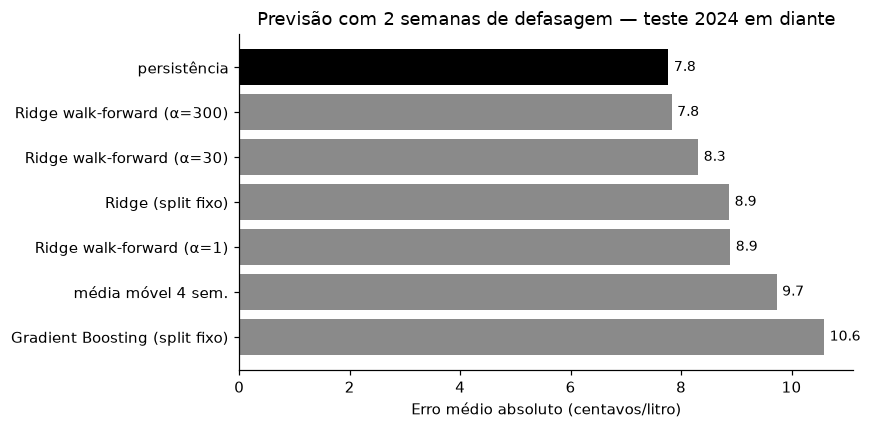

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
t = tabela["d = 2"].sort_values()
cores = ["black" if i == "persistência" else "#8a8a8a" for i in t.index]
ax.barh(t.index, t.values, color=cores)
ax.invert_yaxis()
for y, v in enumerate(t.values):
    ax.text(v + 0.1, y, f"{v:.1f}", va="center", fontsize=9)
ax.set_xlabel("Erro médio absoluto (centavos/litro)")
ax.set_title("Previsão com 2 semanas de defasagem — teste 2024 em diante")
fig.tight_layout()
fig.savefig(DOCS / "fig_baseline_mae.png", bbox_inches="tight")
plt.show()

## 4. Leitura dos resultados

- **Nenhum modelo bate a persistência.** Com d = 2, repetir o último preço
  publicado erra em média ~8 centavos/litro; todo o resto erra mais.
- **Mais regularização → mais perto da persistência.** O Ridge walk-forward com
  α alto encolhe os coeficientes para zero, ou seja, converge para "variação
  prevista = 0". O histórico de preço não carrega sinal útil sobre a próxima
  variação.
- **Média móvel perde feio.** Indica que as variações persistem (degraus de
  reajuste), não que sejam ruído que reverte.
- **A defasagem custa caro:** passar de d = 1 para d = 2 aumenta o erro da
  persistência em ~50%. Para o motorista, o preço "atual" que a ANP mostra já
  está velho — por isso o dashboard tem que exibir a data de referência.

**Implicação para o "abastecer agora ou esperar":** com dados só de preço
de bomba, a recomendação honesta é *não prometer previsão*. Os reajustes vêm de
choques externos (preço da Petrobras nas refinarias, ICMS, câmbio). O próximo
passo natural é incorporar anúncios de reajuste da Petrobras como feature —
eles são públicos e saem *antes* de chegar à bomba.

In [6]:
# Quanto o preço anda em 2 semanas? (contexto para a recomendação)
var2 = (indice - indice.shift(2)).dropna() * 100
print("variação do índice em 2 semanas (centavos), 2024+:")
print(var2[var2.index >= CORTE].describe().round(1).to_string())
print(f"\nsemanas com |variação| > 10 centavos: {(var2[var2.index >= CORTE].abs() > 10).mean():.0%}")

variação do índice em 2 semanas (centavos), 2024+:
count    125.0
mean       2.5
std       10.9
min      -21.2
25%       -4.2
50%        0.6
75%        7.0
max       38.5

semanas com |variação| > 10 centavos: 30%
